# 6. Two-parameter continuation

Two-parameter continuation of folds and Hopf points, checked against
closed-form curves:

```text
  1. cusp normal form  x' = h + r x - x^3
       folds lie on 4 r^3 = 27 h^2, meeting at the cusp (h, r) = (0, 0)   [derivation]
  2. Brusselator  x' = a - (b+1) x + x^2 y,  y' = b x - x^2 y
       [10.1063/1.1668896]
       equilibrium (a, b/a); Hopf on b = 1 + a^2                          [derivation]
```

Shows: grabbing an LP or HB point, choosing the second parameter, and
running in both directions along the curve (ds > 0 and ds < 0).
The script version writes auto_two_parameter.png.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pyxpp

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
plt.close(fig)  # drawn into below, shown at the end

## 1. cusp

In [2]:
cusp = pyxpp.load(text="""
x'=h+r*x-x^3
par h=-1,r=1
init x=-1
@ total=50
done
""")
cusp.run()
cusp.run_last()

# one-parameter branch in h at r = 1: an S-shaped curve with two folds
br = cusp.auto.run("h", start="steady", ds=0.01, dsmax=0.05, parmin=-1, parmax=1, nmax=300)
cusp.auto.diagram.plot(y="x", ax=axs[0])
axs[0].set_title("cusp: one parameter (r = 1)")
lp = br.special("LP")[0]
print(f"fold at h = {lp.x:.6f} (exact {2 / (3 * np.sqrt(3)):.6f})")

# Continue that fold in (h, r).  An LP has no menu: AUTO goes straight to a
# two-parameter run.  Run once each way along the curve.
up = cusp.auto.run(grab=lp.label, param2="r", ds=0.01, nmax=300, parmin=-1, parmax=1)
down = cusp.auto.run(grab=lp.label, ds=-0.01)
for c in (up, down):
    h = np.array([p.x for p in c])
    r = np.array([p.par["r"] for p in c])
    print(f"  {len(c)} points, max |4 r^3 - 27 h^2| = {np.abs(4 * r**3 - 27 * h**2).max():.1e}")
    axs[1].plot(h, r, "C0.", ms=3)
rr = np.linspace(0, 2, 200)
hh = 2 * (rr / 3) ** 1.5
axs[1].plot(hh, rr, "C1--", lw=1, label=r"$4r^3=27h^2$")
axs[1].plot(-hh, rr, "C1--", lw=1)
axs[1].set(title="cusp: fold curve", xlabel="h", ylabel="r", xlim=(-1.1, 1.1))
axs[1].legend()

fold at h = 0.384900 (exact 0.384900)


  25 points, max |4 r^3 - 27 h^2| = 1.3e-03
  76 points, max |4 r^3 - 27 h^2| = 1.2e-03


## 2. Brusselator

In [3]:
bru = pyxpp.load(text="""
x'=a-(b+1)*x+x^2*y
y'=b*x-x^2*y
par a=1,b=1
init x=1,y=1
@ total=50
done
""")
bru.run()
bru.run_last()
br = bru.auto.run("b", start="steady", ds=0.01, dsmax=0.05, parmin=0, parmax=5, nmax=300)
hb = br.special("HB")[0]
print(f"Brusselator Hopf at b = {hb.x:.6f} for a = 1 (exact 2)")

# At an HB, XPP asks what to do; "two param" follows the Hopf curve.
up = bru.auto.run(grab=hb.label, choice="two param", param2="a",
                  ds=0.02, parmin=0, parmax=5, nmax=300)
down = bru.auto.run(grab=hb.label, choice="two param", ds=-0.02)
for c in (up, down):
    b = np.array([p.x for p in c])
    a = np.array([p.par["a"] for p in c])
    print(f"  {len(c)} points, a in [{a.min():.3f}, {a.max():.3f}], "
          f"max |b - (1 + a^2)| = {np.abs(b - 1 - a**2).max():.1e}")
    axs[2].plot(b, a, "C0.", ms=3)
aa = np.linspace(0, 2.1, 200)
axs[2].plot(1 + aa**2, aa, "C1--", lw=1, label=r"$b = 1 + a^2$")
axs[2].text(3.2, 0.6, "oscillations")
axs[2].text(0.5, 1.6, "stable\nequilibrium")
axs[2].set(title="Brusselator: Hopf curve", xlabel="b", ylabel="a", xlim=(0, 5))
axs[2].legend(loc="upper right")

fig.tight_layout()

Brusselator Hopf at b = 2.000000 for a = 1 (exact 2)


  70 points, a in [1.000, 2.002], max |b - (1 + a^2)| = 5.3e-04
  300 points, a in [0.086, 1.000], max |b - (1 + a^2)| = 1.1e-04


## The figure

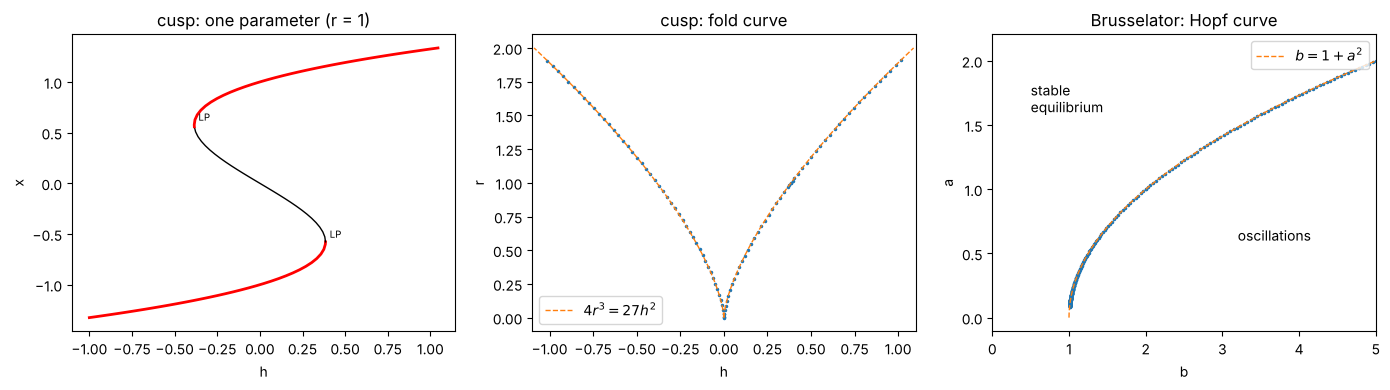

In [4]:
fig